# Análise dos resultados — DQN no Lunar Lander

Este notebook **não treina nada**: ele lê os CSVs gerados pelos scripts de treino
(`python -m dqn.train ...`) em `results/<experimento>/seed_<n>/` e produz os gráficos
e tabelas do relatório. Novos experimentos aparecem automaticamente; basta rodar
o notebook de novo (*Run All*).

As figuras são salvas em `results/figures/`.

**Seções**
1. Carregamento dos resultados
2. Curva de aprendizado da configuração base
3. Comparação por hiperparâmetro
4. Tabela-resumo
5. Comparação com o Stable Baselines3
6. Avaliação final e demonstração do agente

In [1]:
import json
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
assert (ROOT / "configs" / "base.json").exists(), "Abra o notebook a partir da raiz do projeto."
RESULTS = ROOT / "results"
FIG_DIR = RESULTS / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

BASE_EXPERIMENT = "base"        # experimento de referência da busca
FINAL_EXPERIMENT = "final"      # configuração final (configs/final.json)
SB3_EXPERIMENT = "sb3_default"  # pasta gerada pelo script do Stable Baselines3
SOLVED = 200                    # critério de "resolvido" do Lunar Lander

# Paleta categórica testada para daltonismo; a ordem é fixa.
# A configuração base é sempre a primeira cor (azul) em todas as figuras.
PALETTE = ["#257de0", "#f47230", "#00b894", "#f2a600", "#ee7fac", "#008a17", "#6a4ce2", "#ec4647"]
TEXT, TEXT_2, GRID = "#191919", "#666666", "#e5e5e5"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.edgecolor": TEXT_2, "axes.labelcolor": TEXT, "text.color": TEXT,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False, "axes.axisbelow": True,
})

## 1. Carregamento dos resultados

Para cada experimento, o notebook compara o `config.json` salvo com `configs/base.json`
e descobre **automaticamente** quais hiperparâmetros foram alterados. Assim, o nome da
pasta não importa para o agrupamento dos gráficos.

In [2]:
BASE_CONFIG = json.loads((ROOT / "configs" / "base.json").read_text(encoding="utf-8"))
IGNORE_KEYS = {"seed", "device", "eval_freq", "eval_episodes"}


def load_results(results_dir=RESULTS):
    """Lê todos os eval.csv. Retorna (DataFrame longo, dict experimento -> parâmetros alterados)."""
    frames, changes = [], {}
    for eval_csv in sorted(results_dir.glob("*/seed_*/eval.csv")):
        run_dir = eval_csv.parent
        exp, seed = run_dir.parent.name, int(run_dir.name.split("_")[1])
        df = pd.read_csv(eval_csv)
        if df.empty:
            continue
        df["experiment"], df["seed"] = exp, seed
        frames.append(df)
        cfg_file = run_dir / "config.json"
        if exp not in changes and cfg_file.exists():
            cfg = json.loads(cfg_file.read_text(encoding="utf-8"))
            if "algo" in cfg:  # outro algoritmo (SB3): não é uma variação da base
                changes[exp] = {}
                continue
            changes[exp] = {k: v for k, v in cfg.items()
                            if k in BASE_CONFIG and k not in IGNORE_KEYS and v != BASE_CONFIG[k]}
    if not frames:
        raise FileNotFoundError("Nenhum eval.csv encontrado em results/.")
    return pd.concat(frames, ignore_index=True), changes


evals, changes = load_results()

overview = (evals.groupby("experiment")
            .agg(seeds=("seed", "nunique"), ultimo_passo=("step", "max"))
            .assign(alteracoes=lambda d: [
                ", ".join(f"{k} = {v}" for k, v in changes.get(e, {}).items()) or "(nenhuma)"
                for e in d.index]))
overview

,seeds,ultimo_passo,alteracoes
experiment,,,
base,3,500000,(nenhuma)
batch_128,3,500000,batch_size = 128
batch_32,3,500000,batch_size = 32
buffer_10k,3,500000,buffer_size = 10000
buffer_500k,3,500000,buffer_size = 500000
eps_decay_250k,3,500000,eps_decay_steps = 250000
eps_decay_25k,3,500000,eps_decay_steps = 25000
eps_exp_50k,3,500000,"eps_decay_steps = 50000, eps_schedule = expone..."
eps_min_0.01,3,500000,eps_min = 0.01


## 2. Curva de aprendizado da configuração base

A linha é a média da recompensa de avaliação (10 episódios **sem exploração**, ε = 0)
entre as seeds; a faixa é ± 1 desvio-padrão entre seeds (aparece quando há 2+ seeds).
A linha tracejada marca o critério de resolvido (200).

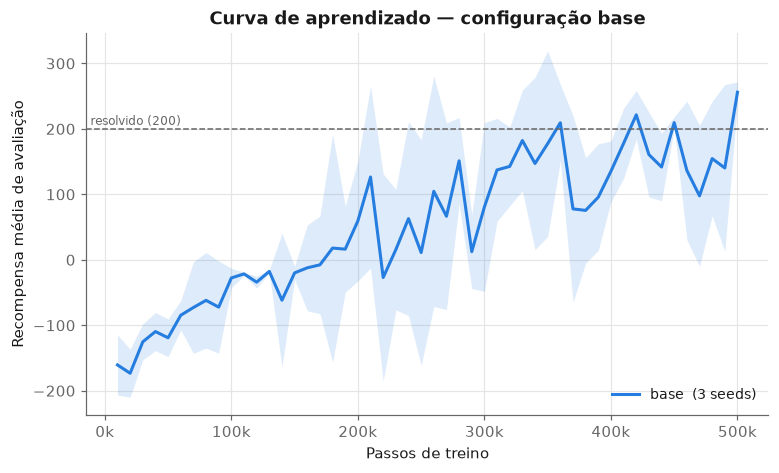

In [3]:
def label_for(exp):
    ch = changes.get(exp, {})
    if exp == SB3_EXPERIMENT:
        return "Stable Baselines3 (padrão)"
    if exp == BASE_EXPERIMENT or not ch:
        return exp
    return ", ".join(f"{k} = {v}" for k, v in ch.items())


def plot_curves(experiments, ax, labels=None, colors=None):
    """Curva média ± desvio entre seeds para cada experimento."""
    for i, exp in enumerate(experiments):
        df = evals[evals.experiment == exp]
        stats = df.groupby("step")["mean_return"].agg(["mean", "std", "count"])
        color = colors[i] if colors else PALETTE[i % len(PALETTE)]
        n = df.seed.nunique()
        label = (labels[i] if labels else label_for(exp)) + f"  ({n} seed{'s' if n > 1 else ''})"
        ax.plot(stats.index, stats["mean"], color=color, label=label)
        if n > 1:
            ax.fill_between(stats.index, stats["mean"] - stats["std"], stats["mean"] + stats["std"],
                            color=color, alpha=0.15, linewidth=0)
    ax.axhline(SOLVED, color=TEXT_2, linestyle="--", linewidth=1)
    ax.text(ax.get_xlim()[0], SOLVED + 6, " resolvido (200)", color=TEXT_2, fontsize=8)
    ax.set_xlabel("Passos de treino")
    ax.set_ylabel("Recompensa média de avaliação")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
    ax.legend(loc="lower right", fontsize=9)


fig, ax = plt.subplots(figsize=(8, 4.5))
plot_curves([BASE_EXPERIMENT], ax)
ax.set_title("Curva de aprendizado — configuração base")
fig.savefig(FIG_DIR / "curva_base.png")
plt.show()

### Recompensa dos episódios de treino

Diferente da avaliação, aqui o agente **está explorando** (ε-greedy), então a curva é
mais ruidosa. Mostramos a média móvel de 50 episódios, com o valor de ε no eixo inferior
para relacionar o desempenho com o decaimento da exploração.

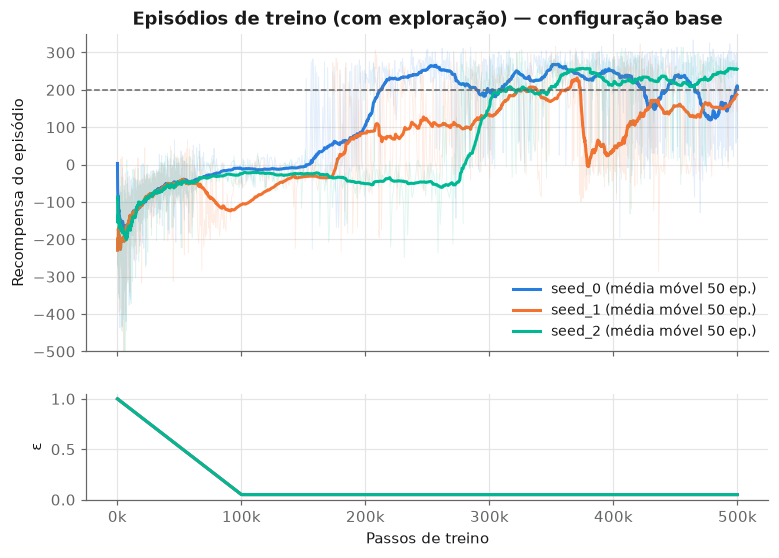

In [4]:
fig, (ax, ax_eps) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True,
                                 gridspec_kw={"height_ratios": [3, 1]})
for i, seed_dir in enumerate(sorted((RESULTS / BASE_EXPERIMENT).glob("seed_*"))):
    ep = pd.read_csv(seed_dir / "train_episodes.csv")
    color = PALETTE[i % len(PALETTE)]
    ax.plot(ep.step, ep["return"], color=color, alpha=0.12, linewidth=0.6)
    ax.plot(ep.step, ep["return"].rolling(50, min_periods=1).mean(), color=color,
            label=f"{seed_dir.name} (média móvel 50 ep.)")
    ax_eps.plot(ep.step, ep.epsilon, color=color)
ax.axhline(SOLVED, color=TEXT_2, linestyle="--", linewidth=1)
ax.set_ylim(-500, 350)
ax.set_ylabel("Recompensa do episódio")
ax.set_title("Episódios de treino (com exploração) — configuração base")
ax.legend(loc="lower right", fontsize=9)
ax_eps.set_ylabel("ε")
ax_eps.set_ylim(0, 1.05)
ax_eps.set_xlabel("Passos de treino")
ax_eps.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
fig.savefig(FIG_DIR / "episodios_treino_base.png")
plt.show()

## 3. Comparação por hiperparâmetro

Os experimentos são agrupados pelo(s) hiperparâmetro(s) que alteram em relação à base.
Cada grupo gera uma figura com a base (azul) e as variações sobrepostas.

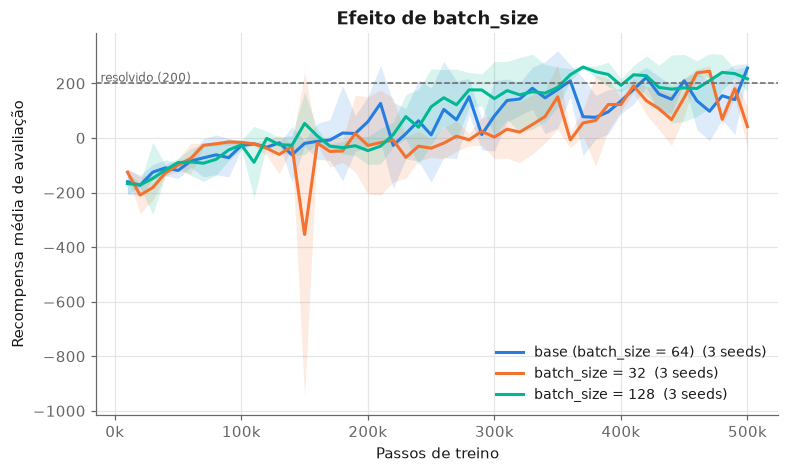

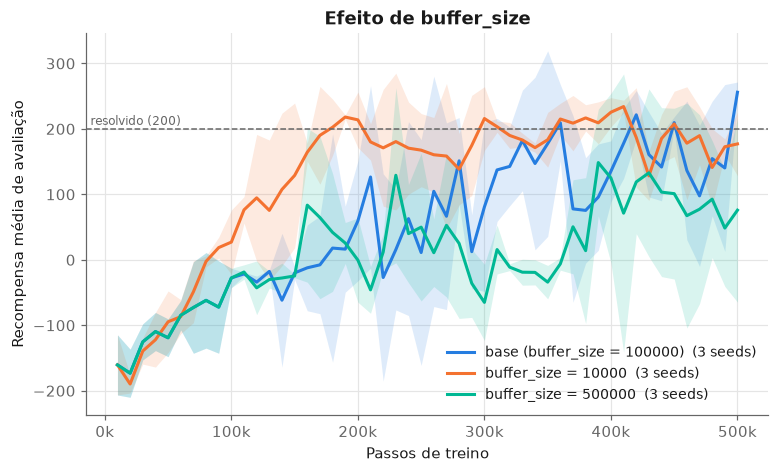

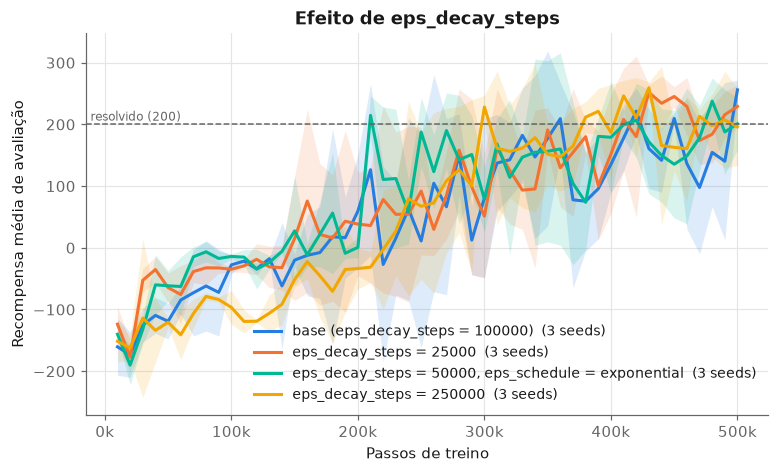

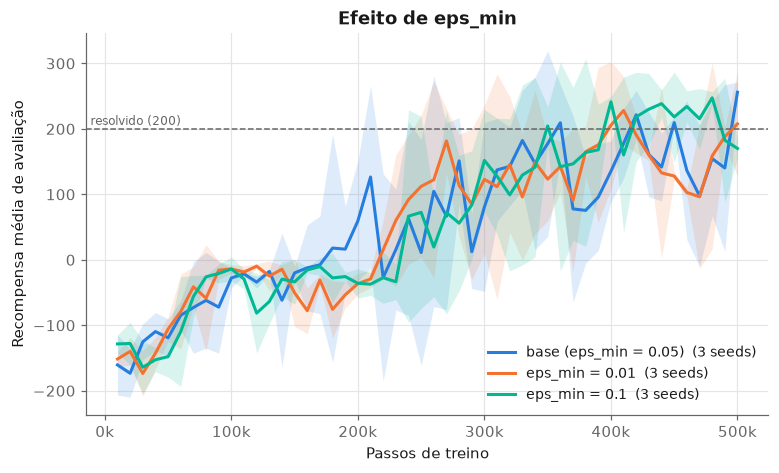

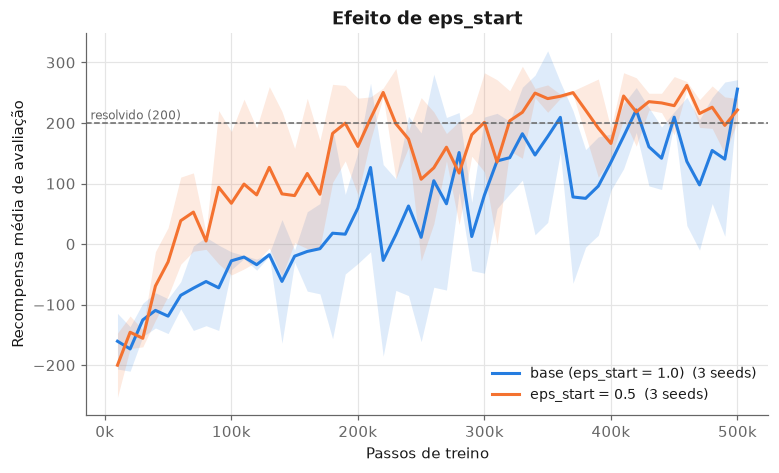

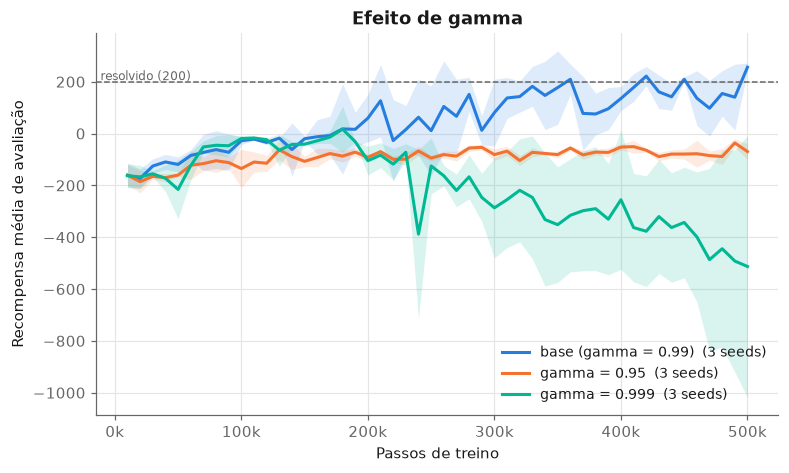

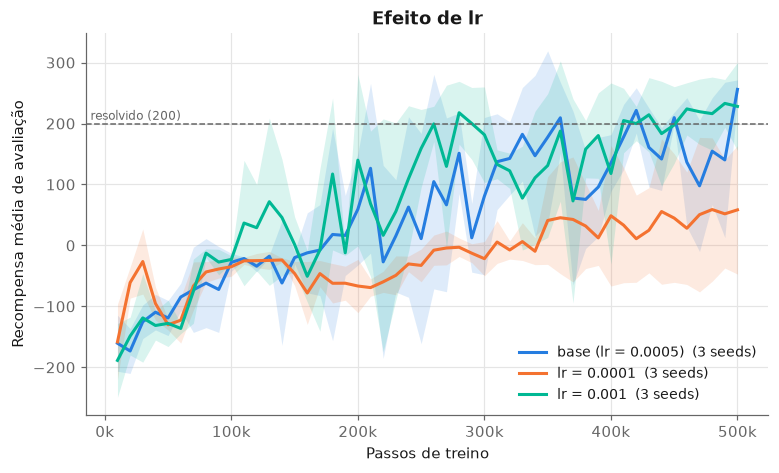

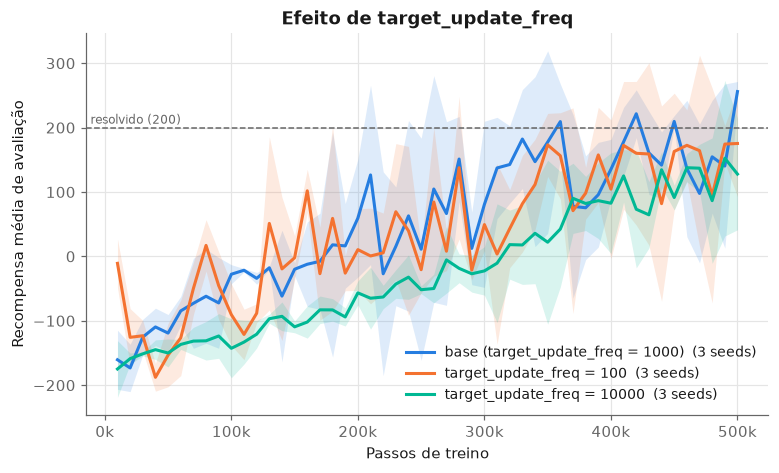

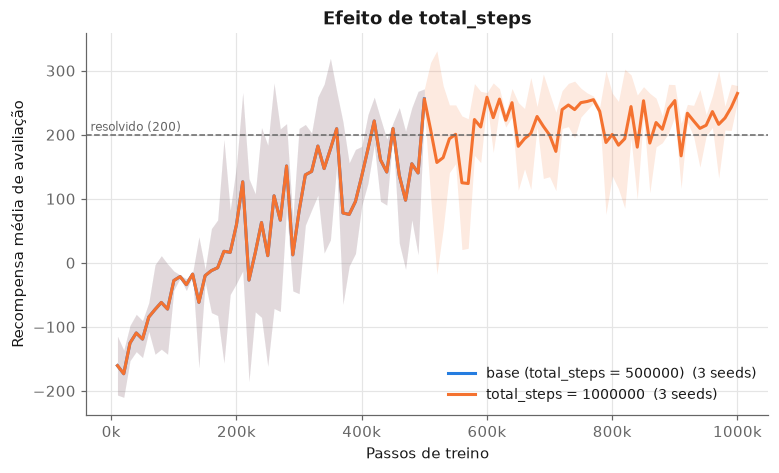

In [5]:
def sort_key(exp):
    v = list(changes.get(exp, {}).values())
    return [(0, x) if isinstance(x, (int, float)) else (1, str(x)) for x in v]


groups = {}
for exp, ch in changes.items():
    if exp in (BASE_EXPERIMENT, FINAL_EXPERIMENT, SB3_EXPERIMENT) or not ch:
        continue
    key = " + ".join(sorted(ch))
    if set(ch) <= {"eps_decay_steps", "eps_schedule"}:
        key = "eps_decay_steps"  # linear e exponencial na mesma figura
    groups.setdefault(key, []).append(exp)

if not groups:
    print("Ainda não há experimentos da busca de hiperparâmetros em results/.")

for param, exps in sorted(groups.items()):
    exps = sorted(exps, key=sort_key)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    plot_curves([BASE_EXPERIMENT] + exps, ax,
                labels=[f"base ({', '.join(f'{k} = {BASE_CONFIG[k]}' for k in param.split(' + '))})"]
                       + [label_for(e) for e in exps])
    ax.set_title(f"Efeito de {param}")
    fig.savefig(FIG_DIR / f"hparam_{param.replace(' + ', '_')}.png")
    plt.show()

## 4. Tabela-resumo

Métricas por experimento (média ± desvio **entre seeds**):

- **final**: média das últimas 5 avaliações (últimos 50 mil passos). É mais robusta do que
  olhar só a última avaliação, já que a curva do DQN oscila.
- **melhor**: maior média de avaliação ao longo do treino.
- **passos até 200**: primeiro passo em que a avaliação atingiu 200 (média das seeds que
  chegaram lá; *seeds ok* indica quantas chegaram).

In [6]:
def summarize(evals, last_k=5):
    rows = []
    for (exp, seed), df in evals.groupby(["experiment", "seed"]):
        df = df.sort_values("step")
        hit = df.loc[df.mean_return >= SOLVED, "step"]
        rows.append({"experiment": exp, "seed": seed,
                     "final": df.mean_return.tail(last_k).mean(),
                     "best": df.mean_return.max(),
                     "steps_to_200": hit.iloc[0] if len(hit) else np.nan})
    per_seed = pd.DataFrame(rows)
    g = per_seed.groupby("experiment")
    table = pd.DataFrame({
        "alteração": [label_for(e) for e in g.groups],
        "seeds": g.seed.count(),
        "final (média)": g.final.mean(), "final (desvio)": g.final.std(),
        "melhor (média)": g.best.mean(),
        "passos até 200": g.steps_to_200.mean(),
        "seeds ok": g.steps_to_200.count(),
    }, index=list(g.groups))
    return table.sort_values("final (média)", ascending=False)


summary = summarize(evals)
summary.to_csv(FIG_DIR / "resumo_experimentos.csv", encoding="utf-8")
summary.style.format({"final (média)": "{:.1f}", "final (desvio)": "{:.1f}",
                      "melhor (média)": "{:.1f}", "passos até 200": "{:,.0f}"}, na_rep="—")

,alteração,seeds,final (média),final (desvio),melhor (média),passos até 200,seeds ok
steps_1m,total_steps = 1000000,3,237.1,21.1,279.4,"293,333",3
eps_start_0.5,eps_start = 0.5,3,224.3,19.6,267.5,"130,000",3
lr_1e-3,lr = 0.001,3,224.1,18.1,269.0,"206,667",3
batch_128,batch_size = 128,3,216.6,62.8,275.3,"310,000",3
final,"lr = 0.001, batch_size = 128, eps_start = 0.5",3,212.7,35.2,278.3,"76,667",3
eps_min_0.1,eps_min = 0.1,3,210.0,22.0,265.3,"286,667",3
eps_decay_25k,eps_decay_steps = 25000,3,206.4,17.2,264.5,"276,667",3
eps_decay_250k,eps_decay_steps = 250000,3,195.0,43.4,264.0,"270,000",3
eps_exp_50k,"eps_decay_steps = 50000, eps_schedule = exponential",3,190.7,56.4,249.6,"223,333",3
buffer_10k,buffer_size = 10000,3,171.7,15.8,262.6,"173,333",3


## 5. Comparação com o Stable Baselines3

Compara a configuração final do nosso DQN com o DQN do Stable Baselines3 na
configuração padrão. Os dois são avaliados com o **mesmo protocolo** (`dqn.evaluate`:
mesmos episódios e seeds de avaliação). Esta seção é preenchida quando existir a pasta
`results/sb3_default/`.

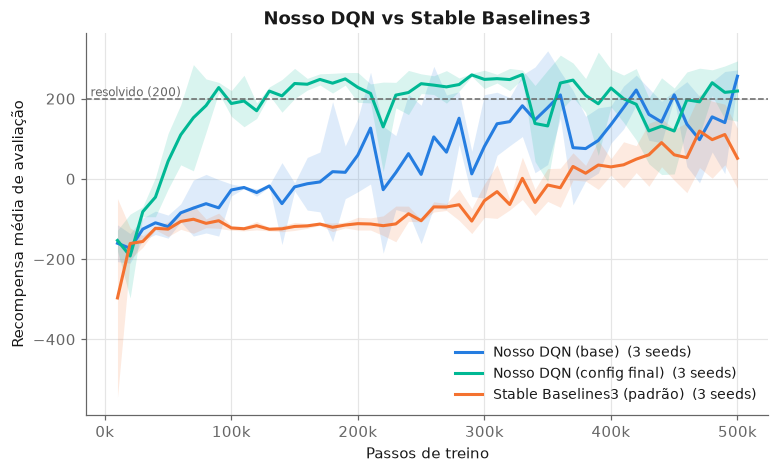

,alteração,seeds,final (média),final (desvio),melhor (média),passos até 200,seeds ok
base,base,3,157.033333,63.667987,261.036667,293333.333333,3
final,"lr = 0.001, batch_size = 128, eps_start = 0.5",3,212.708667,35.159082,278.303333,76666.666667,3
sb3_default,Stable Baselines3 (padrão),3,86.362667,77.489707,139.976667,470000.000000,1


In [7]:
if (RESULTS / SB3_EXPERIMENT).exists():
    fig, ax = plt.subplots(figsize=(8, 4.5))
    exps = [BASE_EXPERIMENT, FINAL_EXPERIMENT, SB3_EXPERIMENT]
    labels = ["Nosso DQN (base)", "Nosso DQN (config final)", "Stable Baselines3 (padrão)"]
    if FINAL_EXPERIMENT == BASE_EXPERIMENT:
        exps, labels = [BASE_EXPERIMENT, SB3_EXPERIMENT], ["Nosso DQN (base)", labels[2]]
    colors = [PALETTE[0], PALETTE[2], PALETTE[1]] if len(exps) == 3 else [PALETTE[0], PALETTE[1]]
    plot_curves(exps, ax, labels=labels, colors=colors)
    ax.set_title("Nosso DQN vs Stable Baselines3")
    fig.savefig(FIG_DIR / "comparacao_sb3.png")
    plt.show()
    display(summary.loc[exps])
else:
    print(f"results/{SB3_EXPERIMENT}/ ainda não existe — rode o script do SB3 primeiro.")

## 6. Avaliação final e demonstração

O melhor modelo da configuração final é avaliado em **100 episódios novos** (política
gulosa, seeds de avaliação fixas). Depois, um episódio é gravado como GIF.

results\final\seed_0\best_model.pt: média = 272.2 ± 37.7 | sucesso (>= 200) = 96%


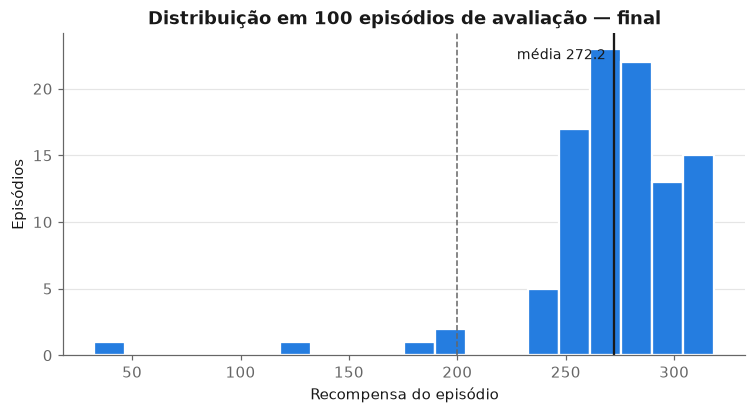

In [8]:
import torch
from dqn.agent import DQNAgent
from dqn.config import DQNConfig
from dqn.evaluate import evaluate_policy

MODEL = RESULTS / FINAL_EXPERIMENT / "seed_0" / "best_model.pt"
ckpt = torch.load(MODEL, map_location="cpu")
cfg = DQNConfig(**ckpt["config"])
agent = DQNAgent(8, 4, cfg)
agent.load(MODEL)

returns = evaluate_policy(agent.greedy_action, cfg.env_id, n_episodes=100)
print(f"{MODEL.relative_to(ROOT)}: média = {returns.mean():.1f} ± {returns.std():.1f} | "
      f"sucesso (>= 200) = {(returns >= SOLVED).mean():.0%}")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(returns, bins=20, color=PALETTE[0], edgecolor="white", linewidth=1.5)
ax.axvline(SOLVED, color=TEXT_2, linestyle="--", linewidth=1)
ax.axvline(returns.mean(), color=TEXT, linewidth=1.5)
ax.text(returns.mean(), ax.get_ylim()[1] * 0.92, f"média {returns.mean():.1f}  ", fontsize=9, ha="right")
ax.set_xlabel("Recompensa do episódio")
ax.set_ylabel("Episódios")
ax.set_title(f"Distribuição em 100 episódios de avaliação — {FINAL_EXPERIMENT}")
ax.grid(axis="x", visible=False)
fig.savefig(FIG_DIR / "distribuicao_avaliacao.png")
plt.show()

Recompensa do episódio: 267.9 | 193 passos | salvo em results\figures\demo.gif


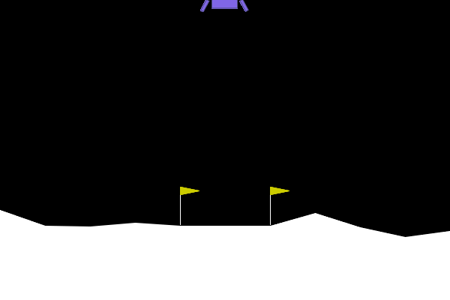

In [9]:
from PIL import Image as PILImage

env = gym.make(cfg.env_id, render_mode="rgb_array")
obs, _ = env.reset(seed=10_000)
frames, done, total = [env.render()], False, 0.0
while not done:
    obs, r, term, trunc, _ = env.step(agent.greedy_action(obs))
    total += r
    done = term or trunc
    frames.append(env.render())
env.close()

gif_path = FIG_DIR / "demo.gif"
imgs = [PILImage.fromarray(f).resize((450, 300)) for f in frames[::2]]
imgs[0].save(gif_path, save_all=True, append_images=imgs[1:], duration=40, loop=0)
print(f"Recompensa do episódio: {total:.1f} | {len(frames)} passos | salvo em {gif_path.relative_to(ROOT)}")
display(Image(filename=str(gif_path)))